In [37]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [38]:
df = pd.read_csv("../data/raw/creditcard.csv")
print(f"(Rows, Columns): {df.shape}")

(Rows, Columns): (284807, 31)


In [39]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [41]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [42]:
print(f"Fraud Percentage : {(df['Class'].value_counts(normalize=True))*100}%")

Fraud Percentage : Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64%


-> there is ~0.17% Fraud Percentage in the Data.

In [43]:
print(f"is there any missing value : {df.isnull().sum()}")

is there any missing value : Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [44]:
print(f"There is total missing value : {df.isnull().sum().sum()}")

There is total missing value : 0


In [45]:
print(f"Total Numbers of Duplicates : {df.duplicated().sum()}")

Total Numbers of Duplicates : 1081


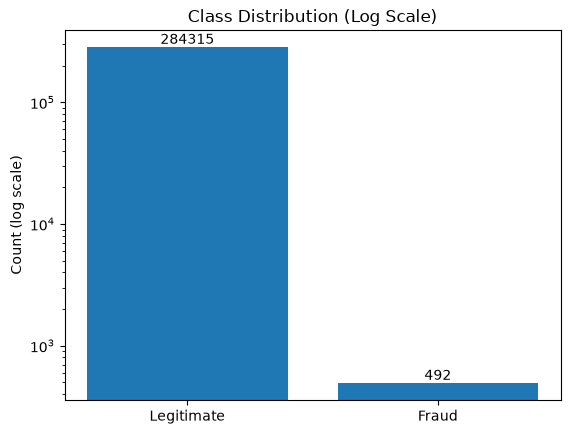

In [60]:
counts=df['Class'].value_counts()
plt.bar(['Legitimate','Fraud'],counts.values)
plt.yscale('log')                  
plt.ylabel('Count (log scale)')
plt.title('Class Distribution (Log Scale)')

for i, v in enumerate(counts.values):
    plt.text(i,v,str(v), ha='center',va='bottom' )

plt.show()



In [61]:
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


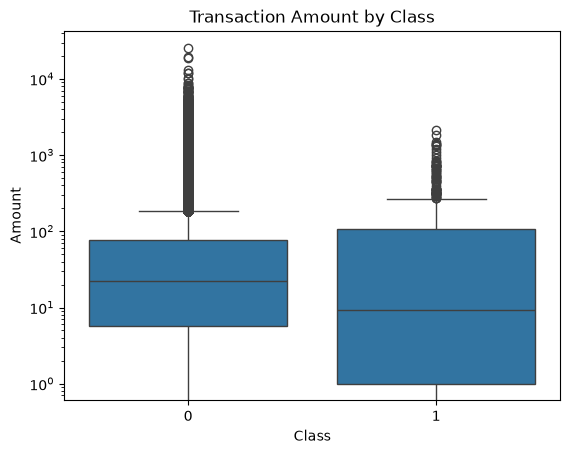

In [67]:
sns.boxplot(x='Class', y='Amount', data=df)
plt.title('Transaction Amount by Class')
plt.yscale('log')  # it used for Scaling the y Axis in Log format

plt.show()

-> Fraudsters often make small test transaction first (₹10–100) to check if a stolen card works, before going big. 

In [69]:
df['Hour'] = df['Time'] / 3600 
df['Hour']

0          0.000000
1          0.000000
2          0.000278
3          0.000278
4          0.000556
            ...    
284802    47.996111
284803    47.996389
284804    47.996667
284805    47.996667
284806    47.997778
Name: Hour, Length: 284807, dtype: float64

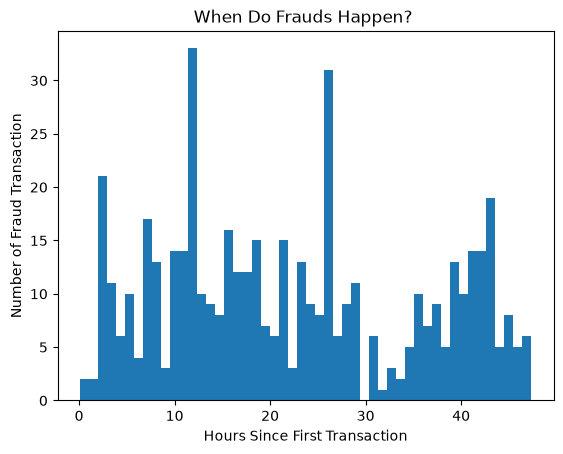

In [75]:
fraud_hours = df[df["Class"] == 1]["Hour"]

plt.hist(fraud_hours,bins=50)
plt.xlabel("Hours Since First Transaction")
plt.ylabel("Number of Fraud Transaction")
plt.title("When Do Frauds Happen? ")
plt.show()

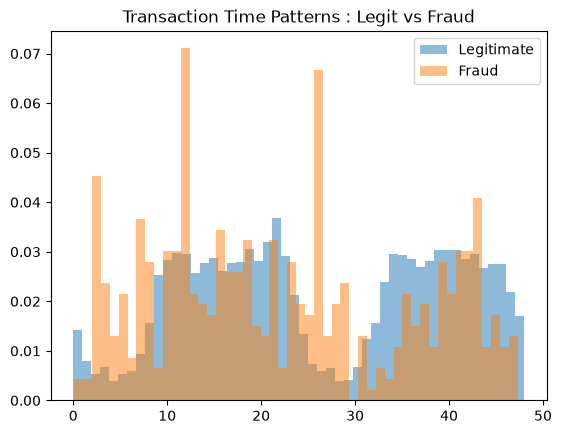

In [76]:
plt.hist(df[df["Class"]==0]["Hour"], bins = 50,alpha=0.5,label="Legitimate",density=True)
plt.hist(df[df["Class"]==1]["Hour"], bins=50,alpha=0.5,label="Fraud",density=True)
plt.legend()
plt.title("Transaction Time Patterns : Legit vs Fraud")
plt.show()

In [77]:
df.corr()["Class"].sort_values()

V17      -0.326481
V14      -0.302544
V12      -0.260593
V10      -0.216883
V16      -0.196539
V3       -0.192961
V7       -0.187257
V18      -0.111485
V1       -0.101347
V9       -0.097733
V5       -0.094974
V6       -0.043643
Hour     -0.012323
Time     -0.012323
V24      -0.007221
V13      -0.004570
V15      -0.004223
V23      -0.002685
V22       0.000805
V25       0.003308
V26       0.004455
Amount    0.005632
V28       0.009536
V27       0.017580
V8        0.019875
V20       0.020090
V19       0.034783
V21       0.040413
V2        0.091289
V4        0.133447
V11       0.154876
Class     1.000000
Name: Class, dtype: float64

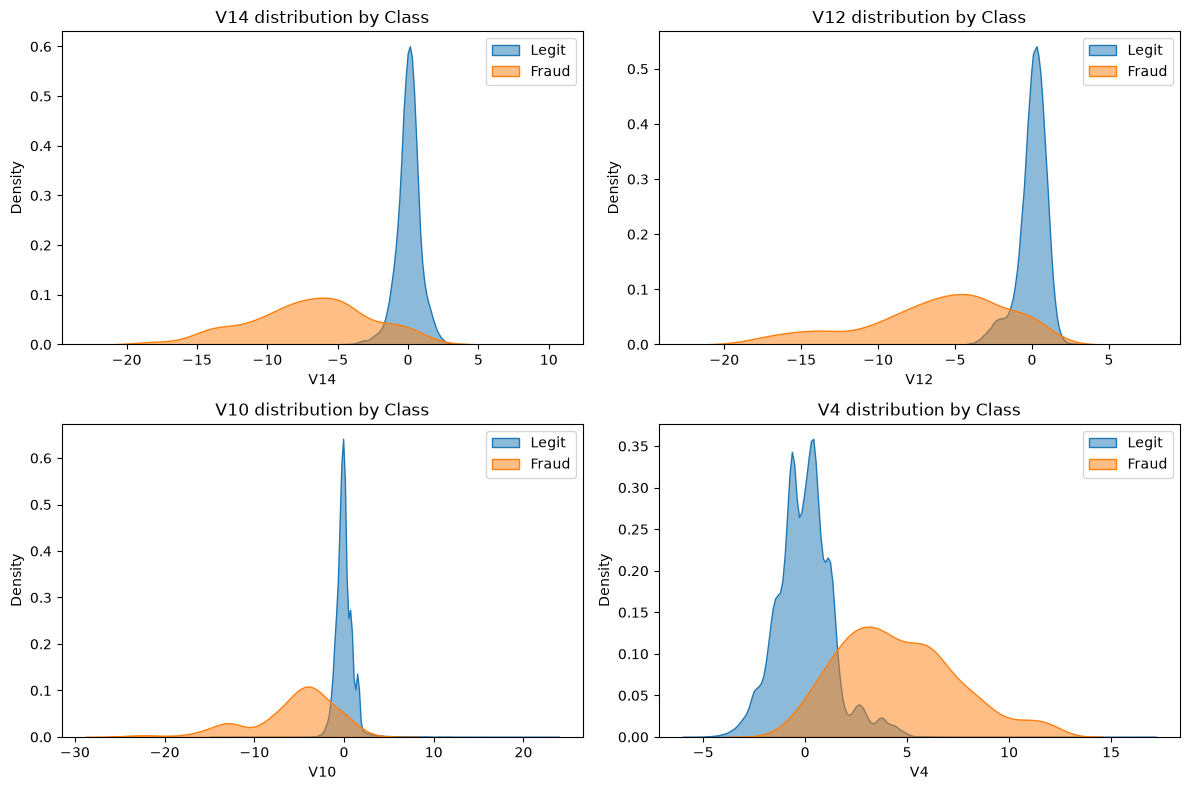

In [78]:
fig , axes = plt.subplots(2,2,figsize=(12,8))

top_features=["V14","V12","V10","V4"]

for ax, col in zip(axes.flat,top_features):
    sns.kdeplot(df[df["Class"]==0][col],ax=ax,label="Legit",fill=True,alpha=0.5)
    sns.kdeplot(df[df["Class"]==1][col],ax=ax,label="Fraud",fill =True,alpha=0.5)
    ax.set_title(f"{col} distribution by Class")
    ax.legend()
    
plt.tight_layout()
plt.show()

## 🔍 EDA Key Findings

### 1. Dataset Overview
- **284,807 transactions**, 31 features (V1–V28 anonymized PCA components + Time + Amount)
- **492 fraudulent transactions → 0.172% fraud rate** (extreme class imbalance ~1:578)
- No missing values ✅

### 2. Duplicates
- **1,081 duplicate rows found** → dropped (standard practice; note: could argue
  repeated fraud attempts are real — documented as a limitation)

### 3. Amount Analysis 💰
- Legit median ≈ **$22** vs Fraud median ≈ **$9.25**
- Fraudsters favor **small amounts** — consistent with the "card testing" pattern
  (small transactions to verify a stolen card works before bigger ones)
- Legit max (~$25,691) far exceeds fraud max (~$2,031)

### 4. Time Analysis ⏰
- Fraud distribution over hours largely **overlaps** with legitimate pattern
- → `Time` is a **weak predictor**; day/night cycles exist but frauds occur
  throughout — no strong clustering signal

### 5. Most Separating Features 🎯
- **V14, V12, V10** (strong negative correlation with fraud) — frauds cluster at
  low/negative values where legit transactions are rare
- **V4, V11** (moderate separation) also useful
- These will likely dominate model feature importance — verified in Phase 4